In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, round as spark_round, unix_timestamp, hour, dayofweek

spark = SparkSession.builder \
    .appName("NYC Taxi Regression") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()

df = spark.read.csv("../data/yellow_tripdata_2016-03.csv", header=True, inferSchema=True)

# Reapply cleaning + feature engineering
df = df.withColumn("trip_duration_min",
    spark_round((unix_timestamp("tpep_dropoff_datetime") - unix_timestamp("tpep_pickup_datetime")) / 60, 2))

df_clean = df.filter(
    (col("trip_duration_min") > 1) & (col("trip_duration_min") < 180) &
    (col("trip_distance") > 0.1) & (col("trip_distance") < 100) &
    (col("fare_amount") > 0) &
    (col("passenger_count") >= 1) & (col("passenger_count") <= 6) &
    (col("pickup_longitude").between(-74.3, -73.7)) &
    (col("pickup_latitude").between(40.5, 40.9))
)

df_clean = df_clean.withColumn("pickup_hour", hour("tpep_pickup_datetime")) \
                   .withColumn("pickup_dayofweek", dayofweek("tpep_pickup_datetime"))

print("Ready. Rows:", df_clean.count())

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/04/25 01:13:56 WARN Utils: Your hostname, giorgos-B550M-AORUS-ELITE, resolves to a loopback address: 127.0.1.1; using 192.168.2.8 instead (on interface enp5s0)
26/04/25 01:13:56 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/04/25 01:13:57 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/04/25 01:13:57 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Ready. Rows: 11891533


In [2]:
from pyspark.ml.feature import VectorAssembler

# These are the input features we'll use to predict trip duration
feature_cols = [
    "trip_distance",
    "pickup_hour",
    "pickup_dayofweek",
    "passenger_count",
    "pickup_longitude",
    "pickup_latitude"
]

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")

df_ml = assembler.transform(df_clean).select("features", "trip_duration_min")

df_ml.show(5)

+--------------------+-----------------+
|            features|trip_duration_min|
+--------------------+-----------------+
|[2.5,0.0,3.0,1.0,...|             7.92|
|[2.9,0.0,3.0,1.0,...|             11.1|
|[19.98,0.0,3.0,2....|             31.1|
|[6.2,0.0,3.0,1.0,...|            16.05|
|[0.7,0.0,3.0,1.0,...|             4.98|
+--------------------+-----------------+
only showing top 5 rows


In [3]:
train_df, test_df = df_ml.randomSplit([0.8, 0.2], seed=42)

print("Training rows:", train_df.count())
print("Test rows:", test_df.count())

Training rows: 9514081


Test rows: 2377452


In [4]:
from pyspark.ml.regression import LinearRegression

lr = LinearRegression(
    featuresCol="features",
    labelCol="trip_duration_min",
    maxIter=10
)

lr_model = lr.fit(train_df)

print("Coefficients:", lr_model.coefficients)
print("Intercept:", lr_model.intercept)

26/04/25 01:16:35 WARN Instrumentation: [c04fca4d] regParam is zero, which might cause numerical instability and overfitting.


Coefficients: [2.483162915805501,0.06019316038585776,0.17910901422152525,0.027489782198912554,-25.986803078323792,8.752351374337772]
Intercept: -2274.2691523740273


In [5]:
from pyspark.ml.evaluation import RegressionEvaluator

predictions = lr_model.transform(test_df)

evaluator_rmse = RegressionEvaluator(
    labelCol="trip_duration_min",
    predictionCol="prediction",
    metricName="rmse"
)

evaluator_r2 = RegressionEvaluator(
    labelCol="trip_duration_min",
    predictionCol="prediction",
    metricName="r2"
)

rmse = evaluator_rmse.evaluate(predictions)
r2 = evaluator_r2.evaluate(predictions)

print(f"Linear Regression Results:")
print(f"  RMSE : {rmse:.4f} minutes")
print(f"  R²   : {r2:.4f}")

Linear Regression Results:
  RMSE : 6.2547 minutes
  R²   : 0.6432


In [6]:
from pyspark.ml.regression import GBTRegressor

gbt = GBTRegressor(
    featuresCol="features",
    labelCol="trip_duration_min",
    maxIter=20,
    maxDepth=5,
    seed=42
)

gbt_model = gbt.fit(train_df)
print("GBT model trained.")

GBT model trained.


In [7]:
gbt_predictions = gbt_model.transform(test_df)

gbt_rmse = evaluator_rmse.evaluate(gbt_predictions)
gbt_r2 = evaluator_r2.evaluate(gbt_predictions)

print(f"Gradient Boosted Trees Results:")
print(f"  RMSE : {gbt_rmse:.4f} minutes")
print(f"  R²   : {gbt_r2:.4f}")

print(f"\nComparison:")
print(f"  Linear Regression → RMSE: {rmse:.4f}, R²: {r2:.4f}")
print(f"  GBT               → RMSE: {gbt_rmse:.4f}, R²: {gbt_r2:.4f}")

Gradient Boosted Trees Results:
  RMSE : 5.0952 minutes
  R²   : 0.7632

Comparison:
  Linear Regression → RMSE: 6.2547, R²: 0.6432
  GBT               → RMSE: 5.0952, R²: 0.7632


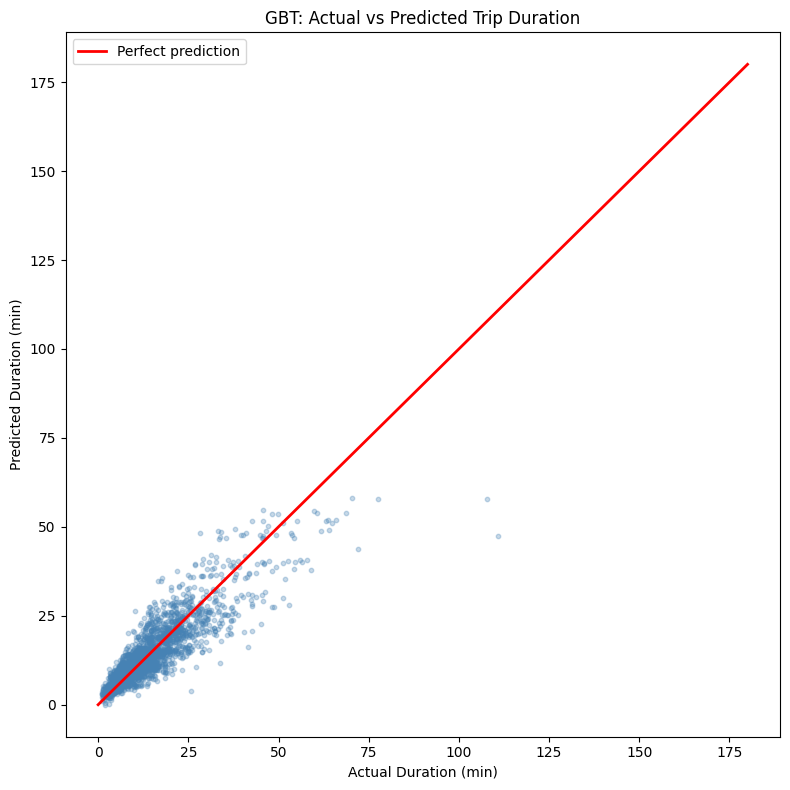

In [8]:
import matplotlib.pyplot as plt

# Sample 2000 points for plotting
sample = gbt_predictions.select("trip_duration_min", "prediction").sample(fraction=0.001, seed=42).toPandas()

plt.figure(figsize=(8, 8))
plt.scatter(sample["trip_duration_min"], sample["prediction"], alpha=0.3, s=10, color="steelblue")
plt.plot([0, 180], [0, 180], color="red", linewidth=2, label="Perfect prediction")
plt.xlabel("Actual Duration (min)")
plt.ylabel("Predicted Duration (min)")
plt.title("GBT: Actual vs Predicted Trip Duration")
plt.legend()
plt.tight_layout()
plt.savefig("../results/gbt_predictions.png", dpi=150)
plt.show()

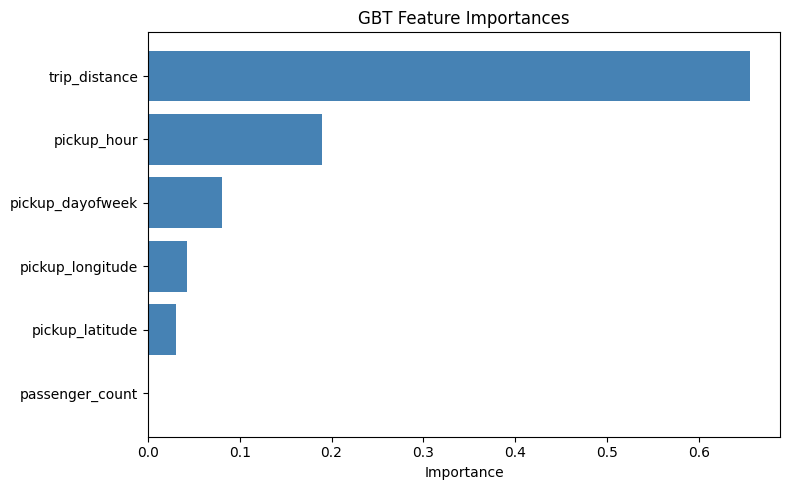

In [9]:
import pandas as pd

feature_names = [
    "trip_distance",
    "pickup_hour",
    "pickup_dayofweek",
    "passenger_count",
    "pickup_longitude",
    "pickup_latitude"
]

importances = pd.DataFrame({
    "feature": feature_names,
    "importance": gbt_model.featureImportances.toArray()
}).sort_values("importance", ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(importances["feature"], importances["importance"], color="steelblue")
plt.xlabel("Importance")
plt.title("GBT Feature Importances")
plt.tight_layout()
plt.savefig("../results/feature_importance.png", dpi=150)
plt.show()